In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#load data

df = sns.load_dataset('tips')
print(f"Total Rows: {len(df)}")
print(df.head(20))

Total Rows: 244
    total_bill   tip     sex smoker  day    time  size
0        16.99  1.01  Female     No  Sun  Dinner     2
1        10.34  1.66    Male     No  Sun  Dinner     3
2        21.01  3.50    Male     No  Sun  Dinner     3
3        23.68  3.31    Male     No  Sun  Dinner     2
4        24.59  3.61  Female     No  Sun  Dinner     4
5        25.29  4.71    Male     No  Sun  Dinner     4
6         8.77  2.00    Male     No  Sun  Dinner     2
7        26.88  3.12    Male     No  Sun  Dinner     4
8        15.04  1.96    Male     No  Sun  Dinner     2
9        14.78  3.23    Male     No  Sun  Dinner     2
10       10.27  1.71    Male     No  Sun  Dinner     2
11       35.26  5.00  Female     No  Sun  Dinner     4
12       15.42  1.57    Male     No  Sun  Dinner     2
13       18.43  3.00    Male     No  Sun  Dinner     4
14       14.83  3.02  Female     No  Sun  Dinner     2
15       21.58  3.92    Male     No  Sun  Dinner     2
16       10.33  1.67  Female     No  Sun  Dinner 

In [4]:
# Simple Groupby: One Category
# Question: Whats the average bill for each day?

avg_by_day = df.groupby('day')['total_bill'].mean()
print("\n---Average Bill by Day---")
print(avg_by_day)


---Average Bill by Day---
day
Thur    17.682742
Fri     17.151579
Sat     20.441379
Sun     21.410000
Name: total_bill, dtype: float64


In [6]:
# Sort from highest to lowest
print("\n---Sorted (highest first)---")
print(avg_by_day.sort_values(ascending=False))


---Sorted (highest first)---
day
Sun     21.410000
Sat     20.441379
Thur    17.682742
Fri     17.151579
Name: total_bill, dtype: float64


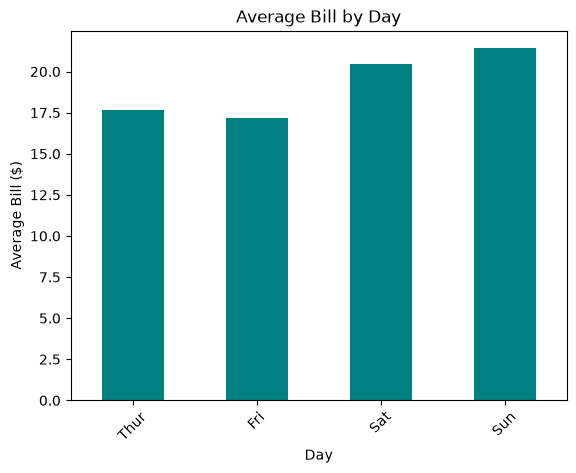

In [8]:
# Data Visualization
avg_by_day.plot(kind='bar', color='teal')
plt.title('Average Bill by Day')
plt.ylabel('Average Bill ($)')
plt.xlabel('Day')
plt.xticks(rotation=45)
plt.show()

In [9]:
# MULTIPLE AGGREGATIONS at once

#get several statistics for each day
stats_by_day = df.groupby('day')['total_bill'].agg([
    'count', # how many records
    'mean',  # average
     'min',  # lowest
     'max',  # highest
     'sum'   # total
])
print("\n--- FULL STATISTICS BY DAY---")
print(stats_by_day)


--- FULL STATISTICS BY DAY---
      count       mean   min    max      sum
day                                         
Thur     62  17.682742  7.51  43.11  1096.33
Fri      19  17.151579  5.75  40.17   325.88
Sat      87  20.441379  3.07  50.81  1778.40
Sun      76  21.410000  7.25  48.17  1627.16


In [10]:
# GROUP BY MULTIPLE COLUMNS

# average bill for each day and time combination
by_day_and_time = df.groupby(['day', 'time'])['total_bill'].mean()

print('Average Bill by Day and Time')
print(by_day_and_time)

Average Bill by Day and Time
day   time  
Thur  Lunch     17.664754
      Dinner    18.780000
Fri   Lunch     12.845714
      Dinner    19.663333
Sat   Dinner    20.441379
Sun   Dinner    21.410000
Name: total_bill, dtype: float64


In [11]:
# convert to readable table
print("As a Table")
pivot = by_day_and_time.unstack() #makes it look like excel pivot
print(pivot)

As a Table
time      Lunch     Dinner
day                       
Thur  17.664754  18.780000
Fri   12.845714  19.663333
Sat         NaN  20.441379
Sun         NaN  21.410000


In [26]:
# Educational example: Student Data

# create fake student dataset
students = pd.DataFrame({
    'student_id': range(1, 21),
    'class': ['A', 'A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'B',
              'A', 'A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'B'],
    'math_score': [85, 67, 92, 78, 88, 72, 95, 68, 81, 77,
                   91, 73, 86, 79, 84, 76, 89, 71, 93, 80],
    'reading_score': [88, 72, 89, 81, 90, 75, 92, 70, 84, 79,
                      87, 76, 91, 82, 85, 78, 88, 73, 94, 83]
})

print("\n--- STUDENT DATA ---")
math_class = students.groupby('class')['math_score'].max()
print(math_class)


--- STUDENT DATA ---
class
A    92
B    95
Name: math_score, dtype: int64


In [19]:
# average score by class
class_avg = students.groupby('class')[['math_score', 'reading_score']].mean()

print("\n---AVERAGE SCORES BY CLASS---")
print(class_avg)


---AVERAGE SCORES BY CLASS---
       math_score  reading_score
class                           
A            82.3           84.1
B            80.2           81.6


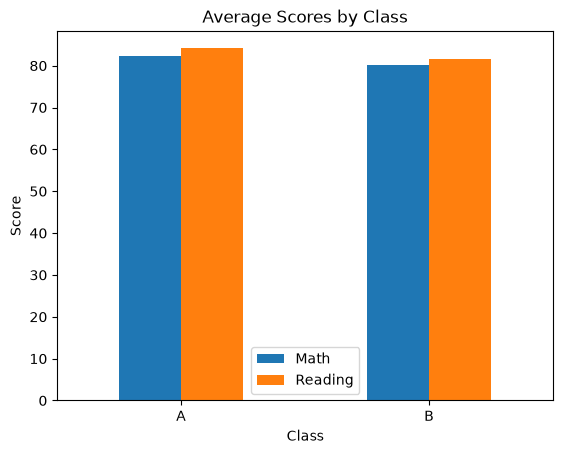

In [20]:
# which class performed better?
class_avg.plot(kind='bar')
plt.title('Average Scores by Class')
plt.ylabel('Score')
plt.xlabel('Class')
plt.legend(['Math', 'Reading'])
plt.xticks(rotation=0)
plt.show()

In [24]:
count_by_time = df.groupby('time')['total_bill'].sum()
print(count_by_time)

time
Lunch     1167.47
Dinner    3660.30
Name: total_bill, dtype: float64


In [36]:
# Part Two: OR logic and advanced filters

# filter Saturday or Sunday
weekend = df[(df['day'] == 'Sat') | (df['day'] == 'Sun')]
print("\n---Weekend Data---")
print(f"Count: {len(weekend)}")

weekday = df[(df['day'] == 'Thur') | (df['day'] == 'Fri')]
print(f"Weekdays: {len(weekday)}")


---Weekend Data---
Count: 163
Weekdays: 81


In [30]:
# better way to do OR with multiple values: .isin()
weekend_v2 = df[df['day'].isin(['Sat', 'Sun'])]
print(f"New :{len(weekend_v)}")

New :163


In [32]:
#Filter: filter bills less than $10 OR greater than $40
extreme_bills = df[(df['total_bill'] < 10) | (df['total_bill'] > 40)]
print("\n----Extreme Bills----")
print(f"Count: {len(extreme_bills)}")
print(extreme_bills[['total_bill', 'tip', 'day']].head())


----Extreme Bills----
Count: 27
    total_bill   tip  day
6         8.77  2.00  Sun
30        9.55  1.45  Sat
43        9.68  1.32  Sun
53        9.94  1.56  Sun
59       48.27  6.73  Sat


In [37]:
#Filter: NOT a specific value
not_saturday = df[~(df['day'] == 'Sat')]
print("\n----NOT SATURDAY---")
print(f"Not Saturday: {len(not_saturday)}")

not_even = df[~(df['tip'] < 2) | (df['tip'] > 4)]
print(f"Not Even: {len(not_even)}")


----NOT SATURDAY---
Not Saturday: 157
Not Even: 199


In [34]:
# Complex example: Weekday dinners with bills $20
complex_filter = df[
    (df['day'].isin(['Mon', 'Tue', 'Wed', 'Thur', 'Fri'])) &
    (df['time'] == 'Dinner') &
    (df['total_bill'] > 20)
]

print(f"Weekday Dinners Over $20: {len(complex_filter)}")

Weekday Dinners Over $20: 6


In [44]:
# Part Three: Sorting Data

# sort by bill amount (lowest to highest)

sorted_bills = df.sort_values('total_bill')
print("Lowest Bills")
print(sorted_bills[['total_bill', 'tip', 'day']].head(10))

Lowest Bills
     total_bill   tip   day
67         3.07  1.00   Sat
92         5.75  1.00   Fri
111        7.25  1.00   Sat
172        7.25  5.15   Sun
149        7.51  2.00  Thur
195        7.56  1.44  Thur
218        7.74  1.44   Sat
145        8.35  1.50  Thur
135        8.51  1.25  Thur
126        8.52  1.48  Thur


In [48]:
# sort highest to lowest
sorted_bills_desc = df.sort_values('total_bill', ascending=False)
print(sorted_bills_desc[['total_bill', 'tip', 'day']].head(10))

     total_bill    tip   day
170       50.81  10.00   Sat
212       48.33   9.00   Sat
59        48.27   6.73   Sat
156       48.17   5.00   Sun
182       45.35   3.50   Sun
102       44.30   2.50   Sat
197       43.11   5.00  Thur
142       41.19   5.00  Thur
184       40.55   3.00   Sun
95        40.17   4.73   Fri


In [49]:
# Final Challenge: Resturant and Analysis Report

print("="*60)
print("RESTAURANT TIPS ANALYSIS REPORT")
print("="*60)

RESTAURANT TIPS ANALYSIS REPORT


In [50]:
# 1. Overall Statistics
print("\n1. OVERALL STATISTICS")
print(f"   Total Records: {len(df)}")
print(f"   Average Bill:  ${df['total_bill'].mean():.2f}")
print(f"   Average Tip:   ${df['tip'].mean():.2f}")
print(f"   Date Range:    {df['day'].unique()}")



1. OVERALL STATISTICS
   Total Records: 244
   Average Bill:  $19.79
   Average Tip:   $3.00
   Date Range:    ['Sun', 'Sat', 'Thur', 'Fri']
Categories (4, str): ['Thur', 'Fri', 'Sat', 'Sun']


In [52]:
# 2. Daily Breakdown
print("\n2. Revenue by Day")
daily_revenue = df.groupby('day')['total_bill'].agg(['count', 'sum', 'mean'])
daily_revenue.columns = ['Orders', 'Total_Revenue', 'Avg_Bill']
print(daily_revenue.sort_values('Total_Revenue', ascending=False))


2. Revenue by Day
      Orders  Total_Revenue   Avg_Bill
day                                   
Sat       87        1778.40  20.441379
Sun       76        1627.16  21.410000
Thur      62        1096.33  17.682742
Fri       19         325.88  17.151579


In [55]:
# 3. Best Performers
print("\n3. Best Performers")
best_day = daily_revenue['Total_Revenue'].idxmax()
print(f"  Highest Revenue day: {best_day} (${daily_revenue.loc[best_day, 'Total_Revenue']:.2f})")


3. Best Performers
  Highest Revenue day: Sat ($1778.40)


In [56]:
# The Period Comparison
print("\n4. Lunch Vs Dinner")
time_comparison = df.groupby('time')[['total_bill', 'tip']].mean()
print(time_comparison)


4. Lunch Vs Dinner
        total_bill       tip
time                        
Lunch    17.168676  2.728088
Dinner   20.797159  3.102670


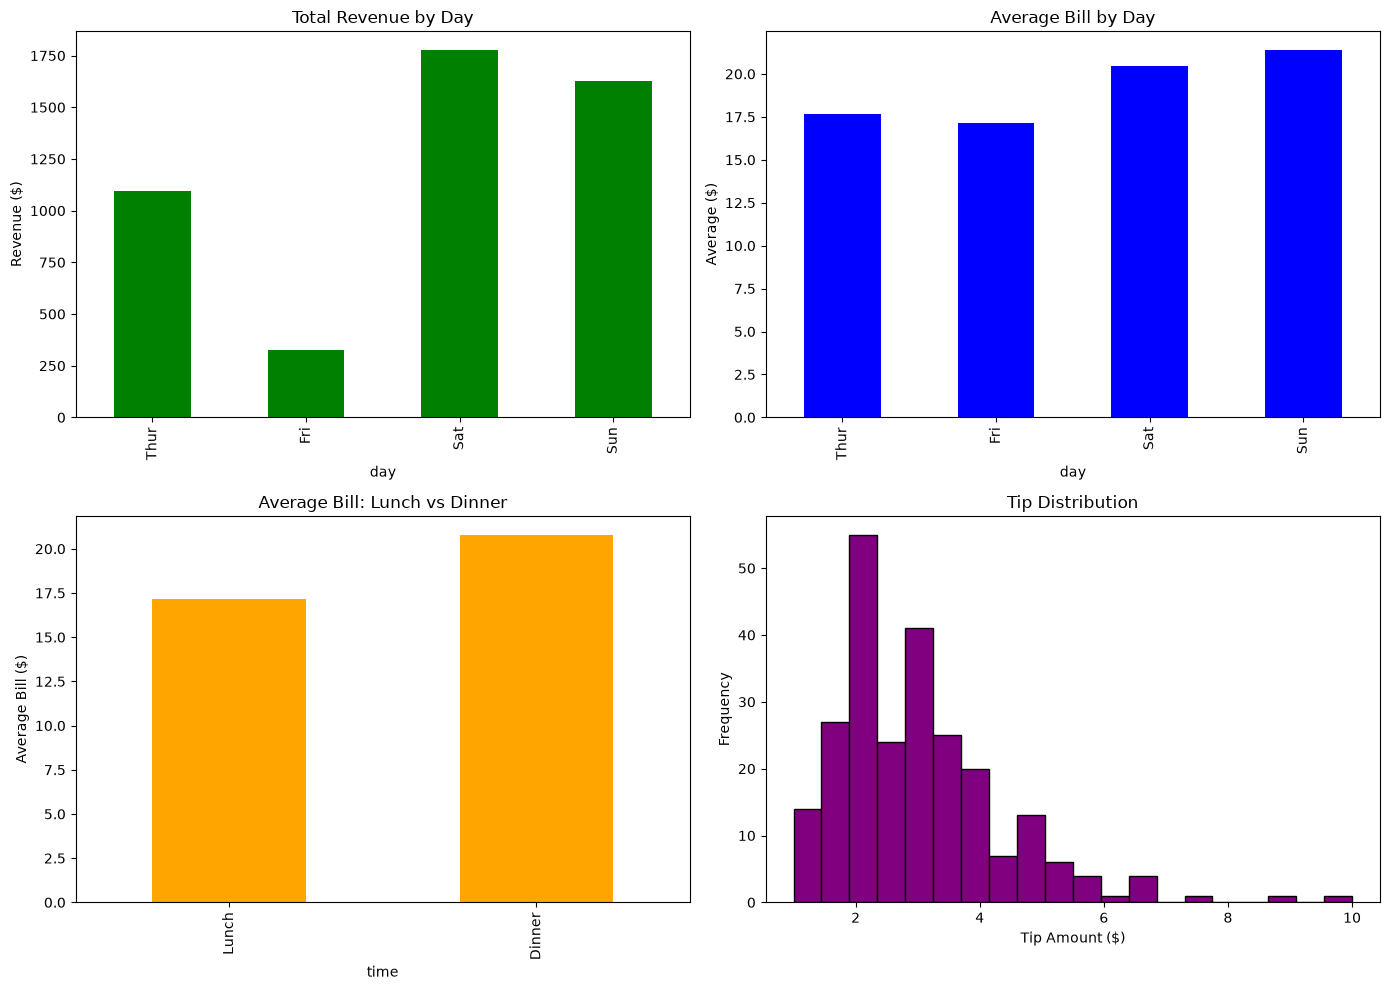


END OF REPORT


In [59]:
#5 Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
#Chart 1: Revenue by Day
daily_revenue['Total_Revenue'].plot(kind='bar', ax=axes[0, 0], color='green')
axes[0, 0].set_title('Total Revenue by Day')
axes[0, 0].set_ylabel('Revenue ($)')

# Chart 2: Average bill by day
daily_revenue['Avg_Bill'].plot(kind='bar', ax=axes[0, 1], color='blue')
axes[0, 1].set_title('Average Bill by Day')
axes[0, 1].set_ylabel('Average ($)')

# Chart 3: Lunch vs Dinner
time_comparison['total_bill'].plot(kind='bar', ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Average Bill: Lunch vs Dinner')
axes[1, 0].set_ylabel('Average Bill ($)')

# Chart 4: Tip distribution
axes[1, 1].hist(df['tip'], bins=20, color='purple', edgecolor='black')
axes[1, 1].set_title('Tip Distribution')
axes[1, 1].set_xlabel('Tip Amount ($)')
axes[1, 1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("END OF REPORT")
print("="*60)
